In [1]:
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt
X = np.random.rand(200).reshape(100,2)#np.array([[1, 2], [1, 4], [1, 0],[10, 2], [10, 4], [10, 0]])

import numpy as np
import joblib
import importlib
import matplotlib.pyplot as plt
import os 
import pickle
import bayes_logistic as bl
from collections import defaultdict
import warnings
warnings.filterwarnings("ignore")
from tqdm import trange, tqdm
import math

os.chdir('/Users/eochoa/Documents/Research_Abuj/ASD/Code/')

import pandas as pd
from utils import *
#from linear_utils import *
from logistic_utils import *
from GP_utils import *
from linear_utils import *
import expt_utils as expt_utils
from sklearn.preprocessing import normalize
from sklearn.datasets import load_iris
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture
from scipy.special import expit, logit
import sklearn
import seaborn as sns
# importlib.reload(expt_utils)
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import pairwise_distances

from scipy.stats import multivariate_normal

In [108]:
import math
def gen_data(N):
    E = np.random.exponential(.01,N)
    Theta = np.random.rand(N) * 2 * math.pi
    Gamma = np.sqrt(E.cumsum()) / (math.pi)
    x = np.array([np.cos(Theta) * Gamma, np.sin(Theta) * Gamma]).T

    #x = np.concatenate(S_list)

    #N = 100
    p = 2
    theta = np.random.rand(p)
    expit = lambda x: 1/(1+np.exp(-x))
    #x = np.random.multivariate_normal(np.zeros(p),np.eye(p)+np.ones((p,p))*.5,N)
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    p = expit(f)
    y = np.random.binomial(1,p)
    return x, y, theta
X, y,theta = gen_data(1000)

In [220]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2):

    #N = 10000
    #p = 10
    theta = np.random.rand(p)
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    #x = np.random.rand(p*N).reshape(N, p)
    
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    #f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    #plt.scatter(x[:,0], x[:,1], c=y)
    return x, y, theta

In [126]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2):

    theta = 5*np.random.rand(p)
    x = np.random.multivariate_normal(np.zeros(p), .3*np.eye(p), N)
    f = x @ theta
    #f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    #plt.scatter(x[:,0], x[:,1], c=y)
    return x, y, theta

In [82]:
X, y,theta = gen_data(1000)
kmeans = KMeans(n_clusters=100, random_state=0).fit(X)

In [5]:
sub_sample = np.random.choice(100,50, replace=False)

In [6]:
ss_X = X[np.isin(kmeans.labels_, sub_sample), :]
ss_y = y[np.isin(kmeans.labels_, sub_sample)]

In [7]:
ss_indx = np.arange(1000)[np.isin(kmeans.labels_, sub_sample)]

In [6]:
X, y, theta = gen_data(1000)

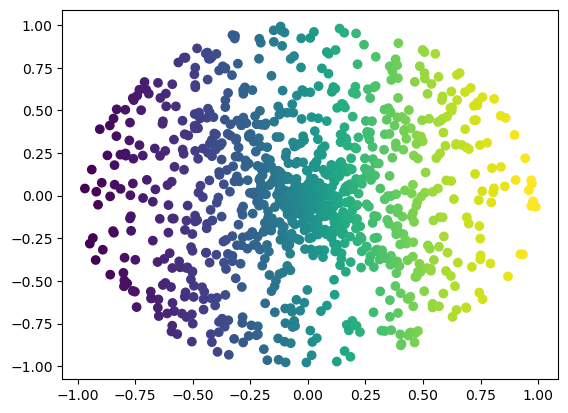

In [7]:
plt.scatter(X[:,0],X[:,1], c=expit(X @ theta))

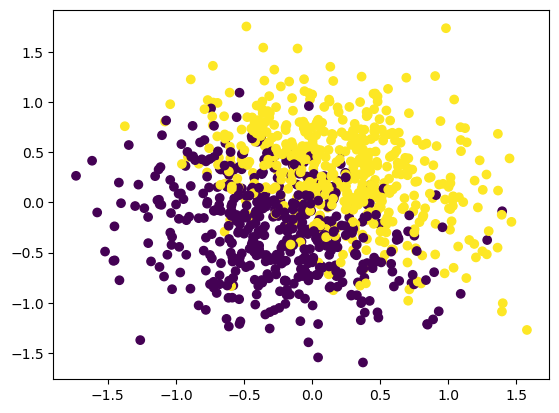

In [204]:
plt.scatter(X[:,0],X[:,1], c=y)

In [125]:
prob_e = np.sort(expit(X @ theta))[::-1]

In [205]:
np.sort(expit(X @ theta))[::-1]

array([9.99990793e-01, 9.99891069e-01, 9.99812485e-01, 9.99740494e-01,
       9.99732076e-01, 9.99490209e-01, 9.99446118e-01, 9.99406107e-01,
       9.99287558e-01, 9.99272976e-01, 9.99155930e-01, 9.99073212e-01,
       9.99015876e-01, 9.98790767e-01, 9.98751583e-01, 9.98728797e-01,
       9.98679904e-01, 9.98667421e-01, 9.98642328e-01, 9.98629878e-01,
       9.98527694e-01, 9.98380640e-01, 9.98313761e-01, 9.98011236e-01,
       9.97947513e-01, 9.97762135e-01, 9.97677678e-01, 9.97487394e-01,
       9.97376770e-01, 9.97215239e-01, 9.97180852e-01, 9.97037828e-01,
       9.96685412e-01, 9.96633641e-01, 9.96520220e-01, 9.96500073e-01,
       9.96447559e-01, 9.96347992e-01, 9.96150318e-01, 9.95982674e-01,
       9.95764130e-01, 9.95582567e-01, 9.95399024e-01, 9.95363064e-01,
       9.95340306e-01, 9.94856605e-01, 9.94652983e-01, 9.94594752e-01,
       9.94196505e-01, 9.94172778e-01, 9.94138824e-01, 9.93949503e-01,
       9.93902455e-01, 9.93732765e-01, 9.93633426e-01, 9.93459823e-01,
      

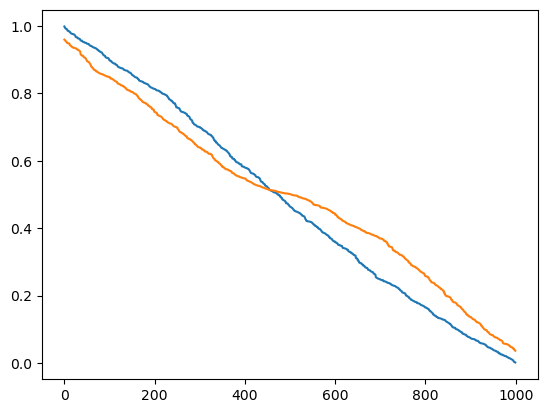

In [217]:
plt.plot(prob_e)
plt.plot(np.sort(expit(X @ theta))[::-1])

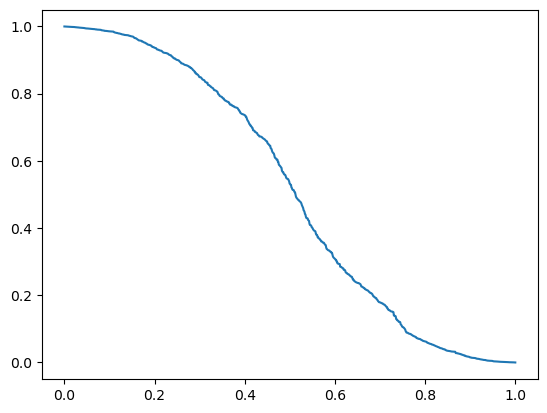

In [207]:
plt.plot(np.linspace(0,1,1000), np.sort(expit(X @ theta))[::-1])

(1.0, 0.0)

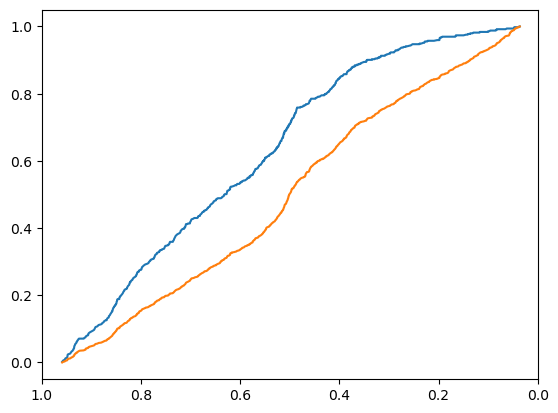

In [218]:
plt.plot(np.sort(expit(X @ theta))[::-1],
         y[np.argsort(expit(X @ theta))[::-1]].cumsum()/y.sum())

plt.plot(np.sort(expit(X @ theta))[::-1], 
         np.linspace(0,1,1000))
plt.xlim(1, 0)
#plt.plot(np.linspace(0,1,1000), np.sort(y)[::-1].cumsum() /y.sum())

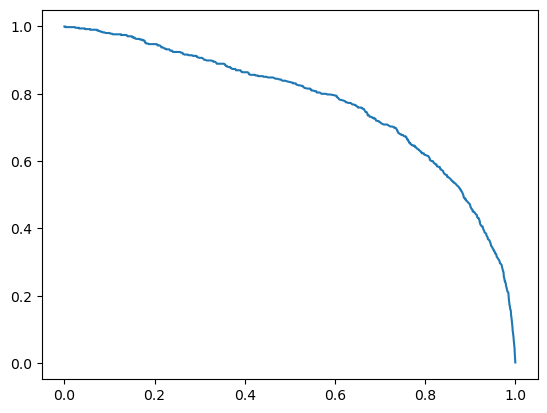

In [212]:
plt.plot(np.sort(expit(X @ theta))[::-1],
         y[np.argsort(expit(X @ theta))[::-1]].cumsum()/y.sum())

In [213]:
algos_dict = {
    'Greedy_logistic': [G_logistic, {'prob_threshold':.5}, 1, 'Greedy_logistic', 'red'],
    'Greedy_logistic_2': [G_logistic, {'n_clus':50, 'ss_size':5, 'optimal_marg':.5}, 1, 'Greedy_logistic_2', 'green']
}

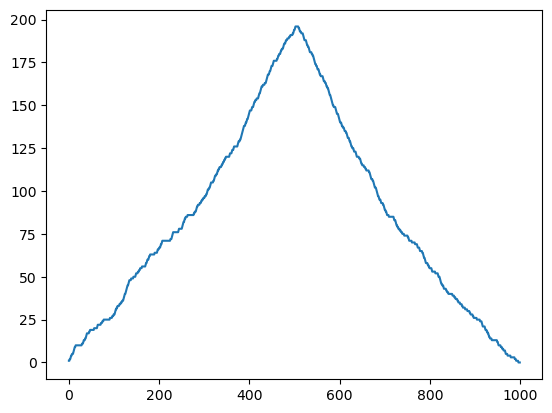

In [116]:
#kmeans = KMeans(n_clusters=200, random_state=0).fit(X)
#sub_sample = np.random.choice(200,20, replace=False)
#actions_0 = list(np.arange(1000)[np.isin(kmeans.labels_, sub_sample)])
#ss_X = X[np.isin(kmeans.labels_, sub_sample), :]
#ss_y = y[np.isin(kmeans.labels_, sub_sample)]

#y_ = (x @ theta[1:])
#y_max = (x @ theta[1:])
#y_max[::-1].sort()

n_row, n_col = y.shape[0], 1
_, n_desc =  X.shape
cutoff = n_desc
T = n_row
prob_dict = {
            "m": n_row,
            "noise": 0.01,
            "d": cutoff
          }
prob = logistic_discover(**prob_dict)
#X = X - X.mean(0)
#X = normalize(X, axis=0, norm='l2')
prob.x = X.copy()
prob.y = y.copy()
t_prob = deepcopy(prob)
solver = G_logistic(t_prob, prob_threshold=0) 
    #reg, act = solver.run(T, refresh=False)[:2]

    #actions_0 = [np.random.choice(np.arange(1000)[kmeans.labels_ == c]) for c in range(10)]


reg_1, rwd, tau = solver.run(T)

plt.plot(reg_1)

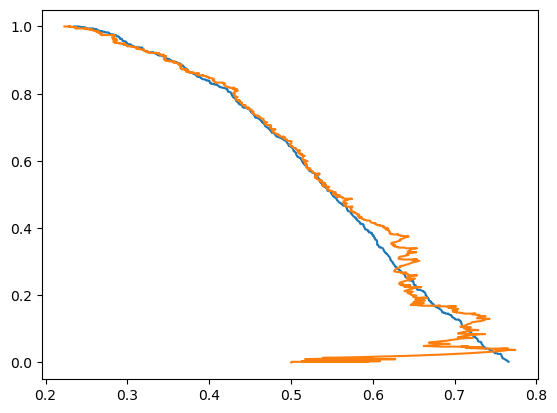

In [118]:
plt.plot(np.sort(expit(X @ theta))[::-1],
y[np.argsort(expit(X @ theta))[::-1]].cumsum()/y.sum())

plt.plot(t_prob.rewards_ev,
np.cumsum(rwd)/y.sum())

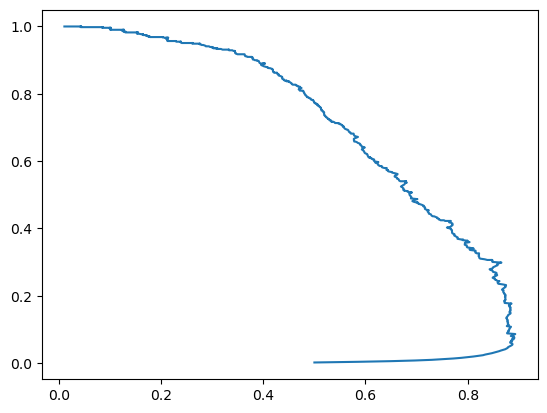

In [45]:
t_prob.rewards_ev

[0.5,
 0.5684132027973604,
 0.6379599936578392,
 0.6795073511224455,
 0.7123904895927533,
 0.7365714119562358,
 0.756993728030477,
 0.7779922921975251,
 0.7905283627894698,
 0.8078733366879192,
 0.8176353860976312,
 0.8188948912624975,
 0.8281399787625553,
 0.8337770634151112,
 0.8415248019619591,
 0.8477739375330687,
 0.8517014889695438,
 0.8567743042210252,
 0.8612313291029902,
 0.8663032214799549,
 0.8712162296464946,
 0.8736033406709045,
 0.8745724352635098,
 0.8722274974538655,
 0.8710554181120206,
 0.8734200853546185,
 0.8737623563091547,
 0.8753484851392035,
 0.8800863008937788,
 0.8824934432757603,
 0.8837996145226774,
 0.8867446865968635,
 0.8884956404110602,
 0.8865808949637395,
 0.8890164304751588,
 0.8924003224571535,
 0.8947356788278386,
 0.8963076081285056,
 0.8976523303662474,
 0.90025236634469,
 0.8979308165673254,
 0.8982472908636849,
 0.8996184501806138,
 0.9016206443625379,
 0.9013036122388159,
 0.9000754486020306,
 0.8985155108008847,
 0.8998950426828635,
 0.9009012

In [46]:
y.sum() - np.sum(rwd)

14

In [21]:
kmeans = KMeans(n_clusters=100, random_state=0).fit(X)
sub_sample = np.random.choice(100,100, replace=False)

In [63]:
kmeans.labels_[np.concatenate([np.argwhere(kmeans.labels_ == i)[0:6] for i in range(100)])]

array([[ 0],
       [ 0],
       [ 0],
       [ 0],
       [ 0],
       [ 0],
       [ 1],
       [ 1],
       [ 1],
       [ 1],
       [ 1],
       [ 1],
       [ 2],
       [ 2],
       [ 2],
       [ 2],
       [ 2],
       [ 2],
       [ 3],
       [ 3],
       [ 3],
       [ 3],
       [ 3],
       [ 3],
       [ 4],
       [ 4],
       [ 4],
       [ 4],
       [ 4],
       [ 4],
       [ 5],
       [ 5],
       [ 5],
       [ 5],
       [ 5],
       [ 5],
       [ 6],
       [ 6],
       [ 6],
       [ 6],
       [ 7],
       [ 7],
       [ 7],
       [ 7],
       [ 7],
       [ 7],
       [ 8],
       [ 8],
       [ 8],
       [ 9],
       [ 9],
       [ 9],
       [ 9],
       [ 9],
       [ 9],
       [10],
       [10],
       [10],
       [10],
       [10],
       [10],
       [11],
       [11],
       [11],
       [11],
       [11],
       [11],
       [12],
       [12],
       [12],
       [12],
       [12],
       [12],
       [13],
       [13],
       [13],
       [13],

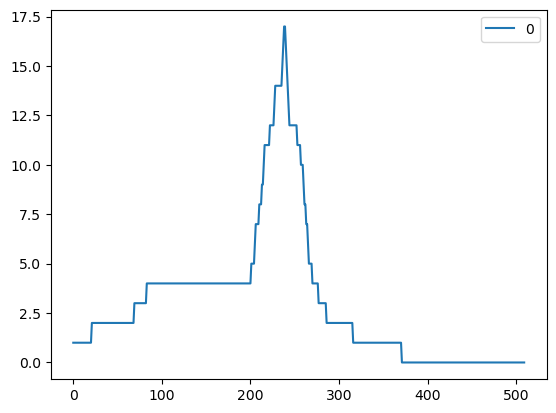

In [152]:
kmeans = KMeans(n_clusters=100, random_state=0).fit(X)
sub_sample = np.random.choice(100,50, replace=False)
#actions_0 = list(np.arange(1000)[np.isin(kmeans.labels_, sub_sample)])
ss_X = X[np.isin(kmeans.labels_, sub_sample), :]
ss_y = y[np.isin(kmeans.labels_, sub_sample)]

#y_ = (x @ theta[1:])
#y_max = (x @ theta[1:])
#y_max[::-1].sort()
n_row, n_col = ss_y.shape[0], 1
_, n_desc =  ss_X.shape
cutoff = n_desc
T = n_row
prob_dict = {
        "m": n_row,
        "noise": 0.01,
        "d": cutoff
      }
prob = logistic_discover(**prob_dict)
ss_X = ss_X - ss_X.mean(0)
ss_X = normalize(ss_X, axis=0, norm='l2')
prob.x = ss_X.copy()
prob.y = ss_y.copy()
t_prob = deepcopy(prob)
solver = G_logistic(t_prob) 
#reg, act = solver.run(T, refresh=False)[:2]

#actions_0 = [np.random.choice(np.arange(1000)[kmeans.labels_ == c]) for c in range(10)]


#reg_1, act = solver.run(T, action_0=actions_0)[:2]
reg_2, rew_2 = solver.run(T)[:2]

#plt.plot(reg_1,label='action_0')
plt.plot(reg_2,label='0')
plt.legend()

In [154]:
(ss_y).sum()

239

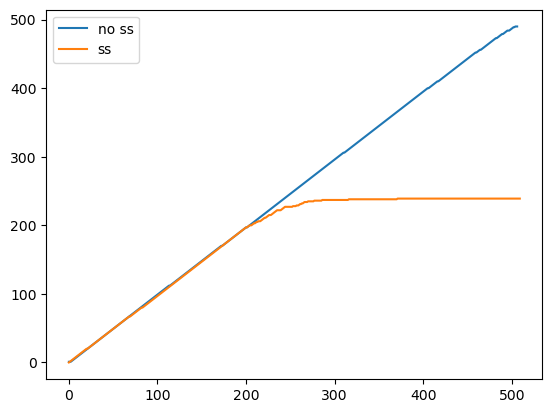

In [153]:
plt.plot(np.array(rew).cumsum(), label='no ss')
plt.plot(np.array(rew_2).cumsum(), label='ss')
plt.legend()

In [27]:
[np.random.choice(np.arange(1000)[kmeans.labels_ == c]) for c in range(2)]

[221, 613]

[584, 44, 522, 80, 896, 900, 684, 164, 874, 674]
[584, 44, 522, 80, 896, 900, 684, 164, 874]
[584, 44, 522, 80, 896, 900, 684, 164]
[584, 44, 522, 80, 896, 900, 684]
[584, 44, 522, 80, 896, 900]
[584, 44, 522, 80, 896]
[584, 44, 522, 80]
[584, 44, 522]
[584, 44]
[584]


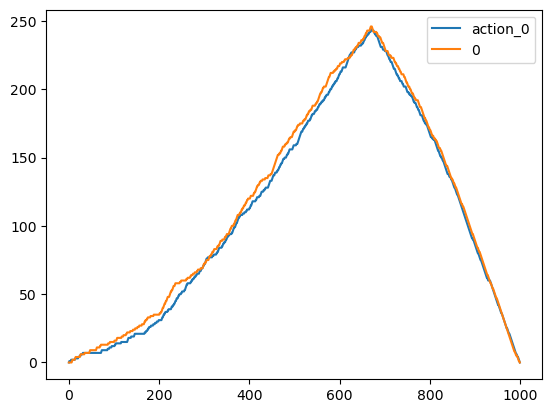

In [60]:
kmeans = KMeans(n_clusters=10, random_state=0).fit(X)
actions_0 = [np.argmin(np.linalg.norm(X - kmeans.cluster_centers_[i], axis=1)) for i in range(10)]#[np.random.choice(np.arange(1000)[kmeans.labels_ == c]) for c in range(10)]

reg_1, act = solver.run(T, action_0=actions_0)[:2]
reg_2, act = solver.run(T)[:2]

plt.plot(reg_1,label='action_0')
plt.plot(reg_2,label='0')
plt.legend()

In [36]:
kmeans.cluster_centers_[0]

array([-0.00857964, -0.05165209])

In [46]:
[np.argmin(np.linalg.norm(X - kmeans.cluster_centers_[i], axis=1)) for i in range(10)]

[395, 280, 588, 735, 244, 966, 54, 83, 113, 858]

In [156]:
np.sqrt(1000)

31.622776601683793

100%|███████████████████████████████████████| 1000/1000 [00:12<00:00, 78.32it/s]


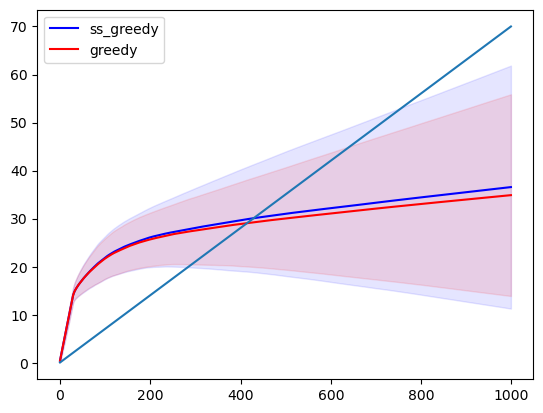

In [281]:
regrets_res_1 = []
regrets_res_2 = []
for j in trange(1000):
    T = 1000
    k = 30
    mu = np.random.rand(k)
    actions = []
    regrets = []
    #rewards = defaultdict(list)
    rwds = np.zeros(k)
    arms_count = np.zeros(k)
    for i in range(T):
        if i < min([k, int(T**0.5)]):
            actions.append(i)
            rwg = np.random.binomial(1,mu[i])
            rwds[i] = rwds[i] + rwg
            arms_count[i] = arms_count[i] + 1
            regrets.append(mu.max() - mu[i])
        else:
            a = np.argmax(rwds/arms_count)
            rwg = np.random.binomial(1,mu[a])
            rwds[a] = rwds[a] + rwg
            arms_count[a] = arms_count[a] + 1
            actions.append(a)
            regrets.append(mu.max() - mu[a])

    regrets_res_1.append(np.cumsum(regrets))
    
    
    actions = []
    regrets = []
    #rewards = defaultdict(list)
    rwds = np.zeros(k)
    arms_count = np.zeros(k)
    for i in range(T):
        if i < k:
            actions.append(i)
            rwg = np.random.binomial(1,mu[i])
            rwds[i] = rwds[i] + rwg
            arms_count[i] = arms_count[i] + 1
            regrets.append(mu.max() - mu[i])
        else:
            a = np.argmax(rwds/arms_count)
            rwg = np.random.binomial(1,mu[a])
            rwds[a] = rwds[a] + rwg
            arms_count[a] = arms_count[a] + 1
            actions.append(a)
            regrets.append(mu.max() - mu[a])
            
    regrets_res_2.append(np.cumsum(regrets))
    
plt.plot(np.mean(regrets_res_1, 0), label='ss_greedy', c = 'b')
plt.fill_between(range(1000), (np.mean(regrets_res_1, 0)-np.std(regrets_res_1, 0)), 
                     (np.mean(regrets_res_1, 0)+np.std(regrets_res_1, 0)), color = 'b', alpha=.1)

plt.plot(np.mean(regrets_res_2, 0), label='greedy', c = 'r')
plt.fill_between(range(1000), (np.mean(regrets_res_2, 0)-np.std(regrets_res_2, 0)), 
                     (np.mean(regrets_res_2, 0)+np.std(regrets_res_2, 0)), color = 'r', alpha=.1)

plt.plot(range(1000), (np.ones(1000)*.07).cumsum())
plt.legend()

100%|█████████████████████████████████████████| 100/100 [00:01<00:00, 80.10it/s]


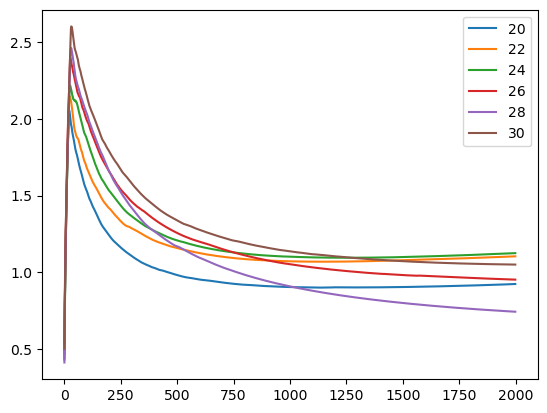

In [331]:
#regrets_res_1
for k in [20,22,24,26,28,30]:
    regrets_res_1 = []
    #regrets_res_2 = []
    for j in trange(100):
        T = 2000
        #k = 30
        mu = np.random.rand(k)
        actions = []
        regrets = []
        #rewards = defaultdict(list)
        rwds = np.zeros(k)
        arms_count = np.zeros(k)
        for i in range(T):
            if i < k:
                actions.append(i)
                rwg = np.random.binomial(1,mu[i])
                rwds[i] = rwds[i] + rwg
                arms_count[i] = arms_count[i] + 1
                regrets.append(mu.max() - mu[i])
            else:
                a = np.argmax(rwds/arms_count)
                rwg = np.random.binomial(1,mu[a])
                rwds[a] = rwds[a] + rwg
                arms_count[a] = arms_count[a] + 1
                actions.append(a)
                regrets.append(mu.max() - mu[a])

        regrets_res_1.append(np.cumsum(regrets))

    plt.plot(np.mean(regrets_res_1, 0) / np.sqrt((np.ones(T)).cumsum()), label = k)
    #plt.axvline(x = k, color = 'b', alpha=.5)
    #plt.axvline(x = k**2, color = 'r', alpha=.5)
    #plt.fill_between(range(1000), (np.mean(regrets_res_1, 0)-np.std(regrets_res_1, 0)), 
    #                     (np.mean(regrets_res_1, 0)+np.std(regrets_res_1, 0)), color = 'b', alpha=.1)

    #plt.plot(np.mean(regrets_res_2, 0), label='greedy', c = 'r')
    #plt.fill_between(range(1000), (np.mean(regrets_res_2, 0)-np.std(regrets_res_2, 0)), 
    #                     (np.mean(regrets_res_2, 0)+np.std(regrets_res_2, 0)), color = 'r', alpha=.1)

#plt.plot(range(100), (np.ones(100)*.5).cumsum())
plt.legend()

In [326]:
1000 ** .5

31.622776601683793

In [320]:
#regrets_res_1
for k in np.arange(2, 40, 2):
    regrets_res_1 = []
    #regrets_res_2 = []
    for j in trange(100):
        T = 2000
        #k = 30
        mu = np.random.rand(k)
        actions = []
        regrets = []
        #rewards = defaultdict(list)
        rwds = np.zeros(k)
        arms_count = np.zeros(k)
        for i in range(T):
            if i < k:
                actions.append(i)
                rwg = np.random.binomial(1,mu[i])
                rwds[i] = rwds[i] + rwg
                arms_count[i] = arms_count[i] + 1
                regrets.append(mu.max() - mu[i])
            else:
                a = np.argmax(rwds/arms_count)
                rwg = np.random.binomial(1,mu[a])
                rwds[a] = rwds[a] + rwg
                arms_count[a] = arms_count[a] + 1
                actions.append(a)
                regrets.append(mu.max() - mu[a])

        regrets_res_1.append(np.cumsum(regrets))

    plt.plot(np.mean(regrets_res_1, 0) / np.sqrt((np.ones(T)).cumsum()), label = k)
    #plt.axvline(x = k, color = 'b', alpha=.5)
    plt.axvline(x = k**2, color = 'r', alpha=.5)
    #plt.fill_between(range(1000), (np.mean(regrets_res_1, 0)-np.std(regrets_res_1, 0)), 
    #                     (np.mean(regrets_res_1, 0)+np.std(regrets_res_1, 0)), color = 'b', alpha=.1)

    #plt.plot(np.mean(regrets_res_2, 0), label='greedy', c = 'r')
    #plt.fill_between(range(1000), (np.mean(regrets_res_2, 0)-np.std(regrets_res_2, 0)), 
    #                     (np.mean(regrets_res_2, 0)+np.std(regrets_res_2, 0)), color = 'r', alpha=.1)

#plt.plot(range(100), (np.ones(100)*.5).cumsum())
plt.legend()

array([[ 9.97457899e-01,  1.36585470e-02, -2.70961363e-03,
         2.18576743e-03,  2.29614222e-03, -5.16406013e-03,
         6.38474633e-04,  6.01330982e-03, -2.88197338e-03,
        -2.32794231e-03],
       [ 1.36585470e-02,  9.94589892e-01, -6.84882418e-03,
         5.74709996e-04,  2.69974591e-03, -5.76006945e-03,
        -2.12900459e-02, -4.37898831e-03,  8.42918693e-03,
         1.05995343e-02],
       [-2.70961363e-03, -6.84882418e-03,  1.00767176e+00,
        -8.44635308e-03,  1.38762223e-02,  2.03200051e-02,
         1.03168563e-02,  1.71121890e-03, -1.55418101e-02,
         1.41461786e-02],
       [ 2.18576743e-03,  5.74709996e-04, -8.44635308e-03,
         9.76123559e-01, -2.15016290e-02, -7.16113547e-04,
         1.88538575e-03,  3.65230431e-04,  3.71350601e-03,
         5.16299727e-03],
       [ 2.29614222e-03,  2.69974591e-03,  1.38762223e-02,
        -2.15016290e-02,  1.00234700e+00, -1.45170431e-02,
        -1.11863636e-02, -2.15370293e-03,  1.32852716e-02,
        -3.

In [221]:
x, y, theta = gen_data(1000)

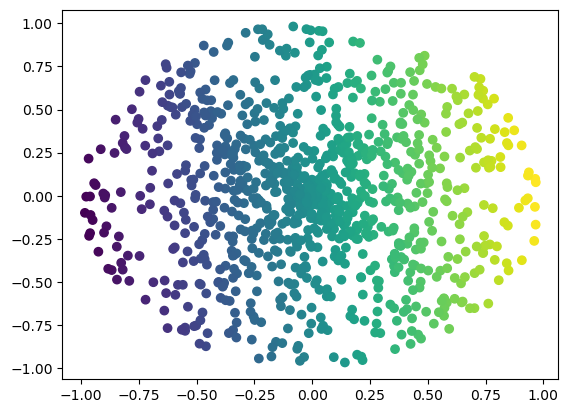

In [222]:
plt.scatter(x[:,0],x[:,1], c=expit(x @ theta))

In [139]:
algos_dict = {
    'TS_logistic': [TS_logistic, {'gamma':1e15, 'prob_threshold':0}, 10, 'TS_logistic', 'darkblue'],   
    'Greedy_logistic': [G_logistic, {'prob_threshold':0}, 1, 'Greedy_logistic', 'red'],
    'Greedy_logistic_2': [G_logistic, {'n_clus':20, 
                                       'ss_size':5,
                                       'optimal_marg':1,
                                       'prob_threshold':0}, 1, 'Greedy_logistic_2', 'green'],
   
}

In [234]:

#prob.y = y.copy()
#t_prob = deepcopy(prob)


#tau_list = {algo:[] for algo in algos_dict}
n_arms = 1000
T = 1000
reg_M_list = {M:[] for M in range(n_arms,n_arms +1)}
for M in trange(n_arms,n_arms+1):
    sol_list = {algo:[] for algo in algos_dict}
    reg_list = {algo:[] for algo in algos_dict}
    act_list = {algo:[] for algo in algos_dict}
    rwd_list = {algo:[] for algo in algos_dict}
    rwd_ev_list = {algo:[] for algo in algos_dict}
    for trial_idx in trange(10):
        
        x, y, theta = gen_data(1000, p=2)
        n_row, n_col = x.shape[0], 1
        _, n_desc =  x.shape
        cutoff = n_desc
        prob_dict = {
                    "m": n_row,
                    "noise": 0.01,
                    "d": cutoff
                      }
        prob = logistic_discover(**prob_dict)
        prob.x = x.copy()
        prob.y = y.copy()
            
        for algo, algo_setup in algos_dict.items():
       
            
            
            t_prob = deepcopy(prob)
            algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                            # print(algo_func)
            if not trial_idx < algo_N_trials:
                continue
            solver = algo_func(t_prob, **algo_params)
            reg, rwd = solver.run(T)[:2]
                    #act_list[algo].append(getattr(solver, "logistic_discover"))
                    #
                    # print(prob.rewards)
            reg_list[algo].append(reg)
            rwd_ev_list[algo].append(solver.prob.rewards_ev)
            rwd_list[algo].append(np.cumsum(rwd))
            act_list[algo].append(solver.prob.actions)
            sol_list[algo].append(solver)
                    #tau_list[algo].append(tau)

            #for algo in algos_dict:
            #algo_label = algos_dict[algo][3]
            #algo_style = algos_dict[algo][4]
    reg_M_list[M] = reg_list

100%|█████████████████████████████████████████████| 1/1 [00:29<00:00, 29.47s/it]


In [237]:
x[0,:] @ sol_list['Greedy_logistic'][0].sigma_t @ x[0,:].T

0.017128437790729006

In [238]:
(x @ sol_list['Greedy_logistic'][0].sigma_t_list[0])[:,None,:].shape

(1000, 1, 2)

In [239]:
(x)[:,:,None].shape

(1000, 2, 1)

In [240]:
idx = np.argsort(((x @ sol_list['Greedy_logistic'][0].sigma_t_list[0])[:,None,:] @ (x)[:,:,None]).flatten())[::-1][:20]

In [242]:
[np.argmin(((x @ sigma)[:,None,:] @ (x)[:,:,None]).flatten()) for sigma in sol_list['Greedy_logistic'][0].sigma_t_list]

[643,
 540,
 540,
 540,
 540,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 540,
 643,
 643,
 540,
 540,
 540,
 540,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643,
 643

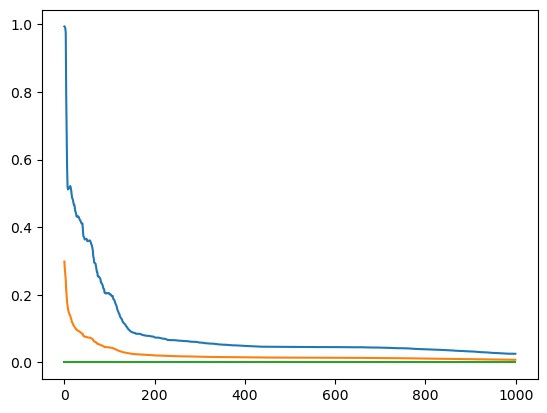

In [244]:
plt.plot([np.max(((x @ sigma)[:,None,:] @ (x)[:,:,None]).flatten()) for sigma in sol_list['Greedy_logistic'][0].sigma_t_list])
plt.plot([np.mean(((x @ sigma)[:,None,:] @ (x)[:,:,None]).flatten()) for sigma in sol_list['Greedy_logistic'][0].sigma_t_list])
plt.plot([np.min(((x @ sigma)[:,None,:] @ (x)[:,:,None]).flatten()) for sigma in sol_list['Greedy_logistic'][0].sigma_t_list])



In [245]:
x[0,:] @ sol_list['Greedy_logistic'][0].sigma_t_list[0] @ x[0,:].T 

0.5971233148007118

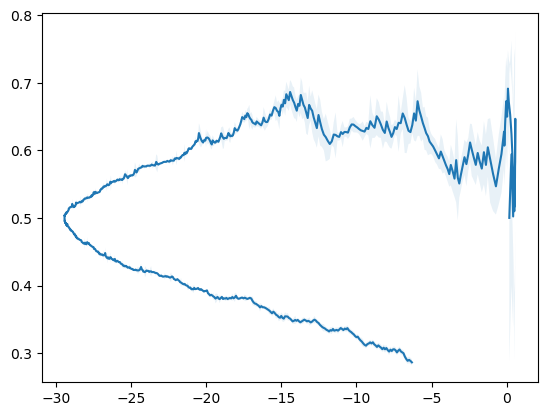

In [247]:
#x_ = np.array(solver.prob.rewards_ev)
x_ = logit(np.array(sol_list['Greedy_logistic'][0].prob.rewards_ev))
#y_ = np.cumsum(solver.prob.rewards)/y.sum()

ci = np.array(sol_list['Greedy_logistic'][0].prob.uncertainty)

plt.plot(y_, expit(x_))
plt.fill_between(y_, expit(x_-ci), expit(x_+ci), alpha=.1)

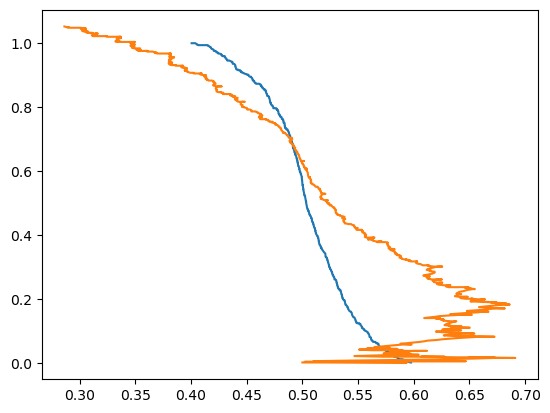

In [249]:
plt.plot(np.sort(expit(x @ theta))[::-1],
y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum())

x_ = sol_list['Greedy_logistic'][0].prob.rewards_ev
y_ = np.cumsum(sol_list['Greedy_logistic'][0].prob.rewards)/y.sum()

plt.plot(x_, y_)



In [45]:
def logit(x):
    return np.log(x / (1-x))

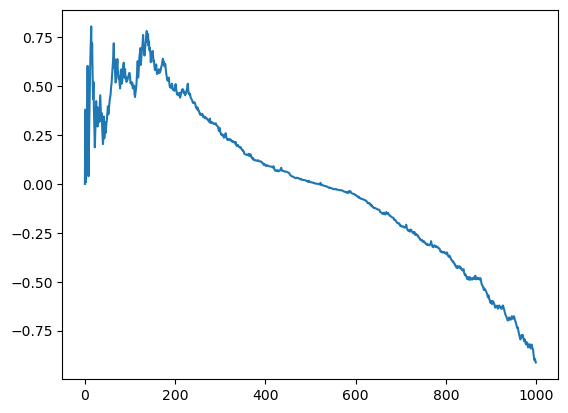

In [251]:
plt.plot(logit(np.array(sol_list['Greedy_logistic'][0].prob.rewards_ev)))

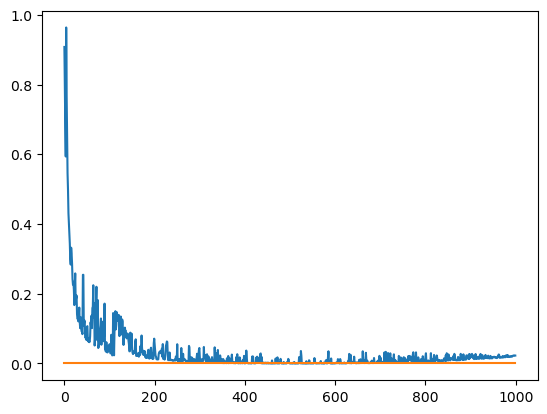

In [253]:
plt.plot(np.array(sol_list['Greedy_logistic'][0].prob.uncertainty))
plt.plot(np.array(sol_list['TS_logistic'][0].prob.uncertainty))

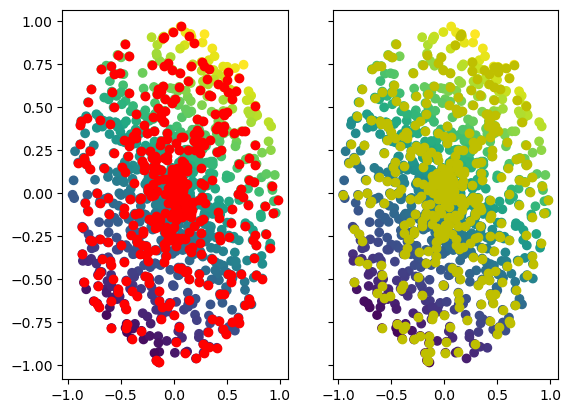

In [226]:
n = 400
idx = act_list['TS_logistic'][6][:n]
idxg = act_list['Greedy_logistic'][0][:n]
fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True)
ax[0].scatter(x[:,0],x[:,1], c=expit(x @ theta))
ax[0].scatter(x[idx,0],x[idx,1], c='r')
ax[1].scatter(x[:,0],x[:,1], c=expit(x @ theta))
ax[1].scatter(x[idxg,0],x[idxg,1], c='y')

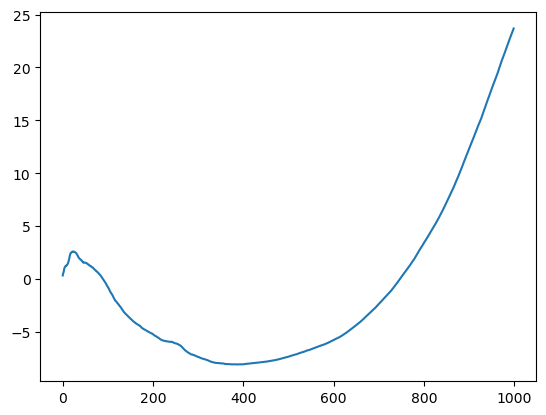

In [227]:
#plt.plot(np.array(rwd_ev_list['TS_logistic'])[:,:,0].T)

plt.plot(np.mean(rwd_ev_list['TS_logistic'], 0).cumsum()
-np.array(rwd_ev_list['Greedy_logistic'])[:,:].T.cumsum())

In [214]:
np.mean(rwd_ev_list['TS_logistic'], 0).shape#[:,:,0].T

(1000, 1)

In [191]:
np.mean(rwd_ev_list['Greedy_logistic'], axis = 0).flatten().cumsum()

array([  0.5       ,   1.20526982,   1.99814791,   2.73663323,
         3.53997212,   4.37370118,   5.21614552,   6.06050759,
         6.8974365 ,   7.74361454,   8.60098214,   9.46291377,
        10.33216229,  11.20629088,  12.08461298,  12.96711564,
        13.85139545,  14.73968252,  15.63218811,  16.52803028,
        17.42535887,  18.32601277,  19.23044968,  20.1381779 ,
        21.04535848,  21.95387634,  22.86393826,  23.77613728,
        24.69038255,  25.60343134,  26.51561775,  27.43018653,
        28.34699993,  29.26430373,  30.1822502 ,  31.10180083,
        32.01778097,  32.93563511,  33.85395545,  34.77320499,
        35.69387129,  36.61686089,  37.53927139,  38.46090492,
        39.3651591 ,  40.27143869,  41.17820782,  42.08518192,
        42.99380008,  43.90206262,  44.80646739,  45.71209355,
        46.61851967,  47.52618932,  48.43583595,  49.34676265,
        50.25485345,  51.1643492 ,  52.07504463,  52.98559439,
        53.89730646,  54.80968722,  55.72137134,  56.63

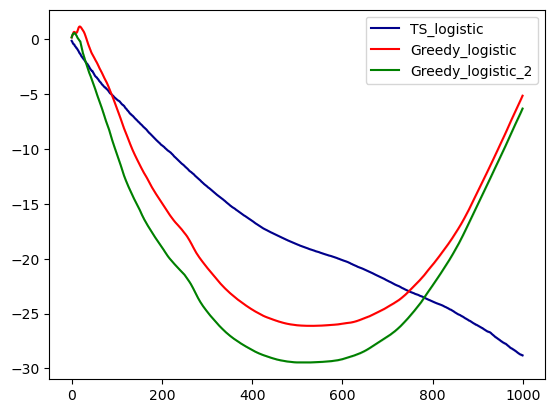

In [231]:
alpha = 0
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.sort(expit(x @ theta))[::-1].cumsum() - np.mean(rwd_ev_list[algo], axis = 0).flatten().cumsum()
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(rwd_ev_list[algo], axis = 0).flatten()/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

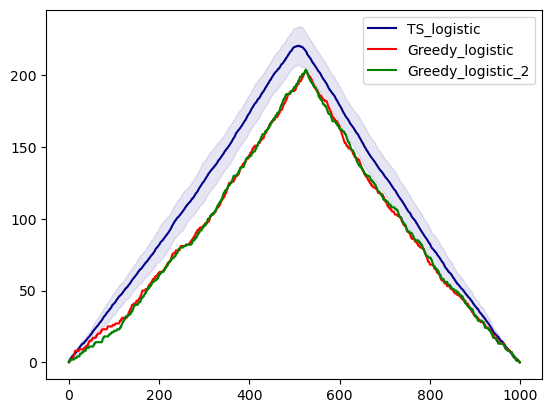

In [229]:
alpha = 0
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

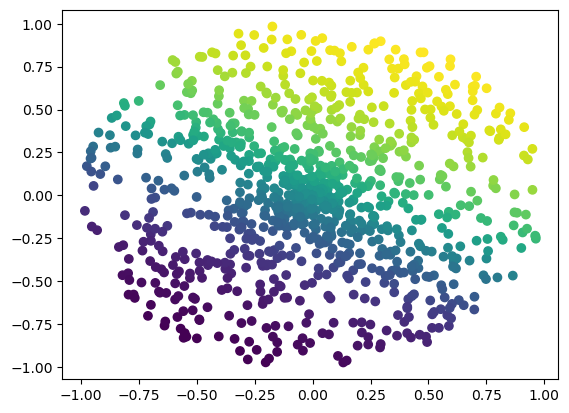

In [46]:
plt.scatter(x[:,0],x[:,1], c=expit(x @ theta))

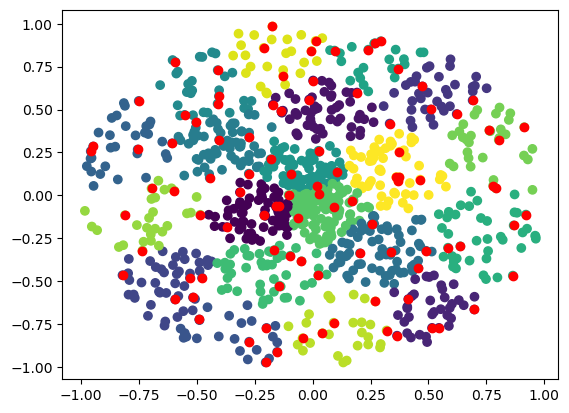

In [47]:
plt.scatter(x[:,0],x[:,1], c=solver.kmeans.labels_)
plt.scatter(x[solver.sub_sample,0],x[solver.sub_sample,1], c='r')

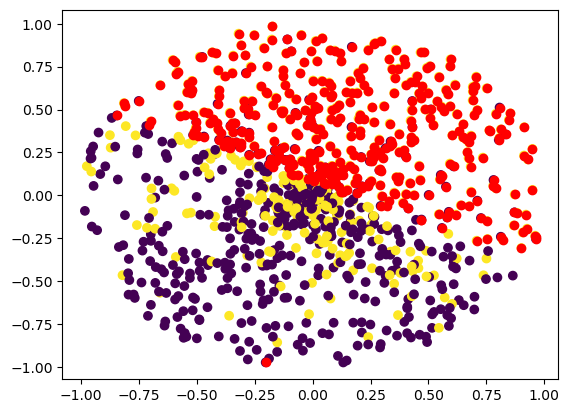

In [54]:
n = 400
plt.scatter(x[:,0],x[:,1], c=y)
plt.scatter(x[solver.prob.actions[:n],0],x[solver.prob.actions[:n],1], c='r')

In [356]:
y_r = x @ theta + .1*np.random.normal(size=1000)

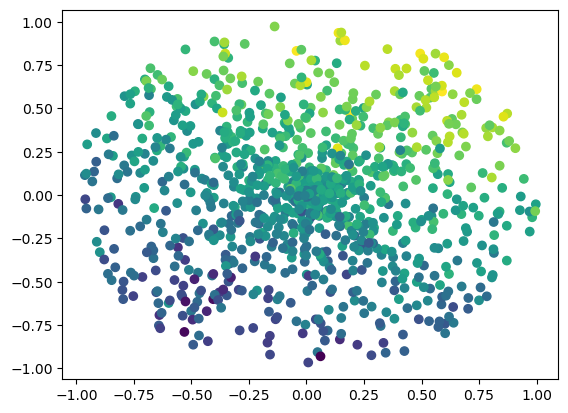

In [357]:
plt.scatter(x[:,0],x[:,1], c=y_r)

In [359]:
np.argmax(smaple_list['norm']), np.max(smaple_list['norm'])

(55115, 1.2763672042046785)

In [360]:
np.argmin(smaple_list['norm']), np.min(smaple_list['norm'])

(17969, 0.7096265718200409)

In [358]:
smaple_list = defaultdict(list)
for i in range(100000):
    id_sample = np.random.choice(1000,100, replace=False) #np.logical_and(x[:,0] > 0, x[:,1] > 0) #
    y_s = y_r[id_sample]
    x_s = x[id_sample,:]
    theta_hat_s = np.linalg.inv(x_s.T @ x_s) @ x_s.T @ y_s
    norm_s = np.linalg.norm(y_s - x_s @ theta_hat_s)
    smaple_list['id'].append(id_sample)
    #smaple_list['y'].append(y_s)
    #smaple_list['x'].append(x_s)
    smaple_list['norm'].append(norm_s)

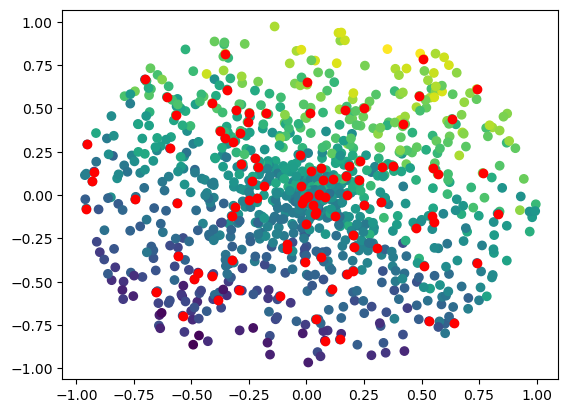

In [330]:
i = 1
plt.scatter(x[:,0],x[:,1], c=y_r)
plt.scatter(x[smaple_list['id'][4280],0],
            x[smaple_list['id'][4280],1], c='r')

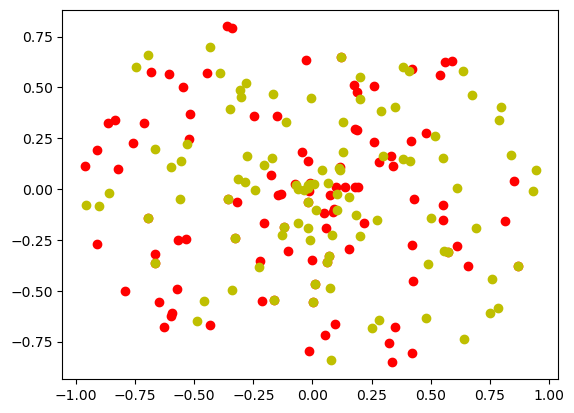

In [361]:
i = 1
#plt.scatter(x[:,0],x[:,1], c=y_r)
plt.scatter(x[smaple_list['id'][55115],0],
            x[smaple_list['id'][55115],1], c='r')

plt.scatter(x[smaple_list['id'][17969],0],
            x[smaple_list['id'][17969],1], c='y')

In [362]:
x_s1 = x[smaple_list['id'][55115],:]
x_s2 = x[smaple_list['id'][17969],:]

In [363]:
np.linalg.eigvals(x.T @ x)

array([175.00545501, 152.66296988])

In [364]:
np.linalg.eigvals(x_s1.T @ x_s1)

array([20.5769281 , 16.62148511])

In [365]:
np.linalg.eigvals(x_s2.T @ x_s2)

array([20.41692748, 12.85674913])